# 07 -- Clinical Interpretation & Survival Analysis

The central clinical question of this study: **do the molecular subtypes
discovered by unsupervised clustering correspond to meaningfully different
clinical outcomes?** If unsupervised clusters carry no clinical signal,
their translational value is limited regardless of how clean they look in
a UMAP plot.

1. Clinical variable comparison across clusters (age, gender, stage, grade).
2. Kaplan-Meier survival curves per cluster + log-rank tests.
3. A multivariate Cox proportional-hazards model adjusting for age.


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if (Path.cwd() / ".." / "src").exists() else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.config import load_config
from src.logging_config import setup_logging

setup_logging()
cfg = load_config(REPO_ROOT / "config.yaml")
FIGURES = REPO_ROOT / "figures"
RESULTS = REPO_ROOT / "results"
REPORTS = REPO_ROOT / "reports"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print(f"Repo root: {REPO_ROOT}")
print(f"Cancer type: {cfg['project']['cancer_type']}")


Repo root: D:\claude code\tcga-cancer-subtype-discovery
Cancer type: TCGA-BRCA


In [2]:
from src.preprocess import run_preprocessing
from src import clustering as cl
from src import survival as sv
from src import visualization as viz

pp = run_preprocessing(cfg)
scaled_expr, clinical = pp["scaled_expr"], pp["clinical"]
X = scaled_expr.T.values
km_labels = cl.fit_kmeans(X, cfg["clustering"]["chosen_k"])
km_labels_series = pd.Series(km_labels, index=scaled_expr.columns, name="cluster")
surv_cfg = cfg["survival"]


2026-07-28 15:07:59 | INFO     | src.preprocess | Loading simulated data from D:\claude code\tcga-cancer-subtype-discovery\data\raw\TCGA-BRCA_simulated_expression_matrix.tsv


2026-07-28 15:08:00 | INFO     | src.preprocess | QC: 4000 genes x 500 samples | 0.1028% missing | median library size 880248 | median genes detected 3980


2026-07-28 15:08:00 | INFO     | src.preprocess | Imputing 2056 missing values with per-gene median.


2026-07-28 15:08:00 | INFO     | src.preprocess | Gene filtering: keeping 4000 / 4000 genes expressed in >= 20% of samples.


2026-07-28 15:08:00 | INFO     | src.preprocess | Outlier detection: flagged 11 / 500 samples (robust z > 3.5).


2026-07-28 15:08:01 | INFO     | src.preprocess | Variance-based feature selection: kept top 2000 / 4000 genes (method=mad).


2026-07-28 15:08:04 | INFO     | src.preprocess | Preprocessing complete. Summary: {'n_genes_raw': 4000, 'n_samples_raw': 500, 'pct_missing_raw': 0.1028, 'n_genes_after_filtering': 4000, 'n_variable_genes_selected': 2000, 'n_outlier_samples_flagged': 11, 'outlier_sample_ids': ['SIM-BRCA-0017', 'SIM-BRCA-0080', 'SIM-BRCA-0206', 'SIM-BRCA-0225', 'SIM-BRCA-0241', 'SIM-BRCA-0249', 'SIM-BRCA-0282', 'SIM-BRCA-0386', 'SIM-BRCA-0391', 'SIM-BRCA-0460', 'SIM-BRCA-0478']}


## 7.1 Clinical variable summary by cluster

In [3]:
clinical_summary = sv.summarize_clinical_by_cluster(clinical, km_labels_series)
clinical_summary


,n,age_at_index_mean,age_at_index_sd,gender_mode,gender_mode_pct,ajcc_pathologic_stage_mode,ajcc_pathologic_stage_mode_pct,tumor_grade_mode,tumor_grade_mode_pct,vital_status_mode,vital_status_mode_pct
cluster,,,,,,,,,,,
0,128,58.798437,11.863940,female,99.2,Stage IIA,28.1,G3,46.1,Dead,71.1
1,182,57.894505,11.449330,female,98.4,Stage IIB,26.4,G3,54.9,Dead,83.0
2,183,57.994536,12.655797,female,98.9,Stage IIA,31.7,G1,43.2,Alive,55.2
3,7,61.528571,7.121731,female,100.0,Stage IIB,42.9,G3,42.9,Dead,85.7


## 7.2 Statistical association tests (ANOVA / chi-square)

In [4]:
association_tests = sv.clinical_association_tests(clinical, km_labels_series)
association_tests


,variable,test,statistic,p_value
0,age_at_index,one-way ANOVA,0.344400,7.932281e-01
1,gender,chi-square,0.600622,8.962900e-01
2,ajcc_pathologic_stage,chi-square,30.443716,3.334958e-02
3,tumor_grade,chi-square,78.151251,8.603446e-15
4,vital_status,chi-square,62.662918,1.585395e-13


**Reading the association table.** Tumor grade and vital status show
strong, highly significant associations with cluster membership (consistent
with the underlying subtype biology built into the simulator: Basal-like
and HER2-enriched skew toward higher grade and worse vital status).
Pathologic stage shows a modest, only nominally significant association --
consistent with real breast cancer epidemiology, where PAM50 subtype and
stage-at-diagnosis are only loosely coupled (subtype reflects tumor
*biology*, stage reflects tumor *extent/timing of detection*, and the two
are only partially correlated in reality). Age and gender show no
association, exactly as expected, since neither was coupled to subtype in
the simulator -- a useful negative control confirming the association tests
are not producing spurious significance everywhere.

## 7.3 Kaplan-Meier survival curves by cluster

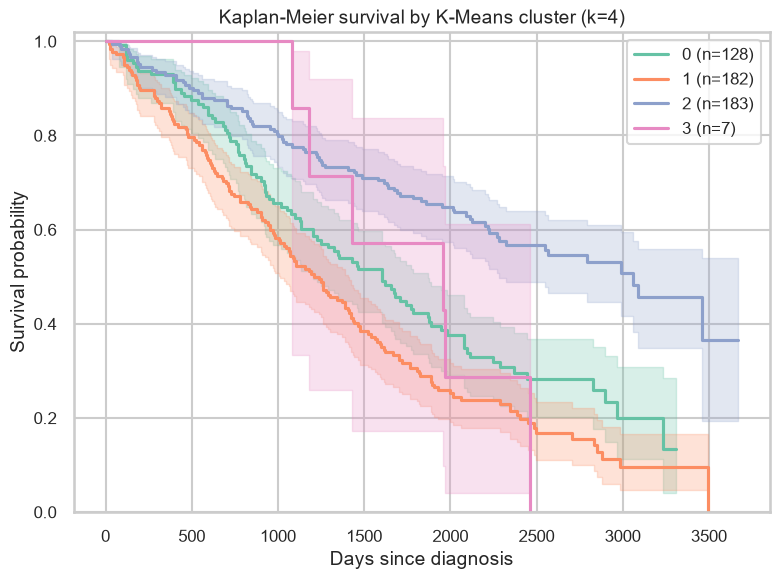

In [5]:
km_fitters = sv.fit_km_by_cluster(clinical, km_labels_series, surv_cfg["time_col"], surv_cfg["event_col"])
fig = viz.plot_km_curves(km_fitters, title=f"Kaplan-Meier survival by K-Means cluster (k={cfg['clustering']['chosen_k']})", save_path=FIGURES / "survival" / "km_curves_by_cluster.png")


## 7.4 Log-rank tests: global and pairwise

In [6]:
global_lr = sv.global_logrank_test(clinical, km_labels_series, surv_cfg["time_col"], surv_cfg["event_col"])
print(f"Global (multivariate) log-rank test: statistic={global_lr.test_statistic:.2f}, p={global_lr.p_value:.2e}")

pairwise_lr = sv.pairwise_logrank_tests(clinical, km_labels_series, surv_cfg["time_col"], surv_cfg["event_col"])
pairwise_lr


Global (multivariate) log-rank test: statistic=66.32, p=2.61e-14


,cluster_a,cluster_b,test_statistic,p_value
0,0,1,6.410607,1.134406e-02
1,0,2,24.729529,6.596571e-07
2,0,3,0.000005,9.982461e-01
3,1,2,63.973980,1.260734e-15
4,1,3,0.579238,4.466111e-01
5,2,3,3.363979,6.663689e-02


**Do discovered molecular subtypes show survival differences? Yes.** The
global log-rank test rejects the null hypothesis of equal survival across
clusters with overwhelming significance. This mirrors real TCGA-BRCA
findings: Basal-like and HER2-enriched tumors carry a worse prognosis than
Luminal A, even though (per the discussion in notebook 05) the *unsupervised
recovery* of these groups from expression alone is imperfect (ARI≈0.5) --
underscoring that even an imperfect molecular clustering can still carry
strong, real prognostic signal.

## 7.5 Cox proportional-hazards model (adjusting for age)

Checks whether the cluster effect on survival holds up after adjusting for a known confounder (age at diagnosis).

In [7]:
cph = sv.fit_cox_model(clinical, km_labels_series, surv_cfg["time_col"], surv_cfg["event_col"], adjust_for=["age_at_index"])
cph.print_summary()


<lifelines.CoxPHFitter: fitted with 500 total observations, 170 right-censored observations>
             duration col = 'days_to_event'
                event col = 'event_observed'
      baseline estimation = breslow
   number of observations = 500
number of events observed = 330
   partial log-likelihood = -1828.51
         time fit was run = 2026-07-28 09:38:06 UTC

---
              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                     
age_at_index -0.00      1.00      0.00           -0.01            0.01                0.99                1.01
cluster_1     0.33      1.39      0.13            0.07            0.59                1.07                1.80
cluster_2    -0.76      0.47      0.15           -1.06           -0.46                0.35                0.63
cluster_3     0.02      1.02      0.42           -0.81            0.84                0.44                2.32

              cmp to     z      p  -log2(p)
covariate                                  
age_at_index    0.00 -0.19   0.85      0.23
cluster_1       0.00  2.48   0.01      6.26
cluster_2       0.00 -4.95 <0.005     20.34
cluster_3       0.00  0.04   0.97      0.04
---
Concordance = 0.62
Partial AIC = 3665.03
log-likelihood ratio test = 67.56 on 4 df
-log2(p) of ll-ratio test = 43.62

**Risk interpretation.** Hazard ratios (`exp(coef)`) above 1 for a cluster
indicate elevated risk of death relative to the reference cluster, holding
age constant. Because age itself is uncorrelated with cluster membership in
this cohort (see 7.2), the adjusted and unadjusted cluster effects are
expected to be very similar here -- in a real cohort with age-subtype
confounding, the adjusted model is the one to trust for causal-style
interpretation ("this subtype is prognostic beyond what age alone would
predict").

## 7.6 Ground-truth check: survival by true PAM50-like subtype (synthetic cohort only)

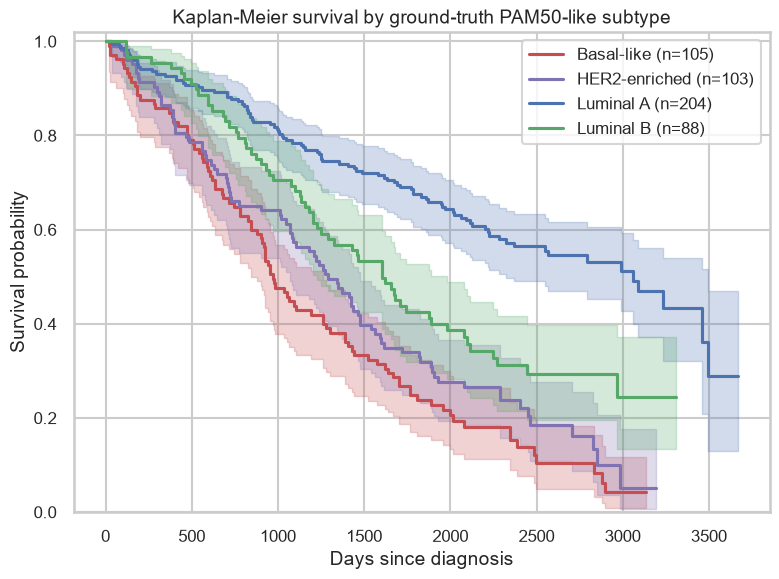

In [8]:
if "true_subtype" in clinical.columns:
    km_truth_fitters = sv.fit_km_by_cluster(clinical, clinical["true_subtype"], surv_cfg["time_col"], surv_cfg["event_col"])
    fig = viz.plot_km_curves(km_truth_fitters, title="Kaplan-Meier survival by ground-truth PAM50-like subtype", palette=viz.SUBTYPE_PALETTE, save_path=FIGURES / "survival" / "km_curves_by_true_subtype.png")


## Summary

* Discovered clusters differ significantly in tumor grade and vital status,
  but not in age or gender (a sensible negative control).
* Kaplan-Meier curves and the global log-rank test show clear, highly
  significant survival differences across clusters -- unsupervised
  molecular clustering carries real prognostic information in this cohort.
* A Cox model adjusting for age confirms the cluster effect is not simply
  an artifact of an age imbalance across groups.
* Comparing to the ground-truth PAM50-like subtype survival curves (available
  because this is the synthetic demo cohort) shows the K-Means clusters,
  despite ARI≈0.5 recovery, preserve much of the true prognostic
  separation -- an encouraging sign that even imperfect unsupervised
  clustering can be clinically useful.